In [80]:
import networkx as nx
from scipy.io import mmread
import pickle

#Data Import
#G = nx.from_scipy_sparse_array(mmread("socfb-Cornell5/socfb-Cornell5.mtx"))
G = pickle.load(open('/home/rh614/PythonRepos/Assignments/Assigments/G.pkl', 'rb'))

In [ ]:
#Simple Network Stats
import numpy as np
N= G.number_of_nodes()
L= G.number_of_edges()
deg = dict(G.degree())
cc = list(dict(nx.clustering(G)).values())

k_avg= np.mean(list(deg.values()))
average_clustering = np.mean(cc)

print("N: ", N)
print("L: ", L)
print("Average Degree: ", k_avg)
print("Average Clustering: ", average_clustering)


G_null = G.copy() #Config Null Model: w/ no self-loops or multi-path
nx.double_edge_swap(G_null, nswap=10 * G_null.number_of_edges(),
                    max_tries=100 * G_null.number_of_edges(), seed=42)

N_null= G_null.number_of_nodes()
L_null= G_null.number_of_edges()
deg_null = dict(G_null.degree())
cc_null = list(dict(nx.clustering(G_null)).values())

k_avg_null= np.mean(list(deg_null.values()))
average_clustering_null = np.mean(cc_null)

print("N_null: ", N_null)
print("L_null: ", L_null)
print("Average Degree (Null Model): ", k_avg_null)
print("Average Clustering (Null Model): ", average_clustering_null)

N:  4047
L:  109566
Average Degree:  54.146775389177165
Average Clustering:  0.9519314689382639
N_null:  4047
L_null:  109566
Average Degree (Null Model):  54.146775389177165
Average Clustering (Null Model):  0.08163857907938307


In [105]:
#Creating a list of null models
list_of_nulls = []
for i in range(1,100):
    null_entry = G.copy()
    nx.double_edge_swap(null_entry, nswap=2*G_null.number_of_edges(),
                    max_tries=4 * G_null.number_of_edges())
    list_of_nulls.append(null_entry)

In [110]:
#Generating Stats based upon many Null Models
N_nulls= []
L_nulls=[]
deg_nulls=[]
cc_nulls=[]
for null in list_of_nulls:
    N_nulls.append(null.number_of_nodes())
    L_nulls.append(null.number_of_edges())
    deg_nulls.append(dict(null.degree()))
    cc_nulls.append(list(dict(nx.clustering(null)).values()))


In [112]:
from itertools import chain

k_avg_null= np.mean(list(chain.from_iterable(item.values() for item in deg_nulls)))#'*' is used to go in one level
average_clustering_null = np.mean(cc_nulls)

print("N_nulls: ", np.mean(N_nulls))
print("L_nulls: ", np.mean(L_nulls))
print("Average Degree (Null Models): ", k_avg_null)
print("Average Clustering (Null Models): ", average_clustering_null)

N_nulls:  4047.0
L_nulls:  109566.0
Average Degree (Null Models):  54.146775389177165
Average Clustering (Null Models):  0.07852417446983646


Super interesting result! The average degree is about the same as the configuration model! This suggests that people are about as much as random.
But! The clustering is incredibly high on reddit. Far higher than random. 

This tells me that Reddit connects people as much as we would expect for its structure.
A follow-up question though is: is this also what we expect offline?

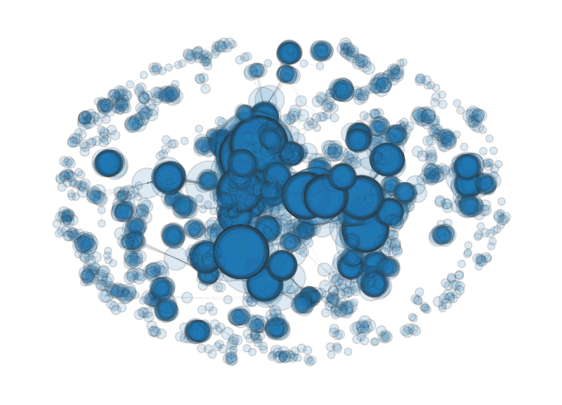

In [82]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,1,figsize=(7,5),dpi=100)

pos = nx.spring_layout(G, scale=20, k=3/np.sqrt(G.order()))
sizes = [20 + 8 * G.degree(n) for n in G.nodes]

nx.draw(G, pos, node_size=sizes, alpha=0.15, width=0.5, edgecolors='.2',
        with_labels=False, font_size='x-small', edge_color='.6',ax=ax)

Here we can see the graph constructed, where nodes are sized by degree (larger is bigger). Here, each node reflects a comment, and size effectively shows us the comments on the posts with the most amount of comments (i.e., highest number of potential connections)

In [ ]:
#Community Detection
import networkx as nx
import numpy as np
from collections import defaultdict
from random import shuffle
import matplotlib.pyplot as plt
import community

partition = community.best_partition(G)#Louvain

# Output the best modularity score
print("Best Modularity: ", community.modularity(partition, G))

# Output the Number of Communities Detected {node_id: community_id}
print("Number of Communities Detected: ",len(np.unique(list(partition.values()))))

# Storing and showing partition as dictionary
G_parts = dict(partition)
print("Partition Dictionary: ", G_parts)
colors_sns = plt.cm.tab20b(np.linspace(0,1,len(np.unique(list(partition.values())))))
colors_nodes = [colors_sns[partition[node]] for node in G.nodes()]

#Repeating analysis for all nulls
partition_nulls=[]
modularity_scores=[]
number_of_communities=[]
for null in list_of_nulls:
    partition_nulls.append(community.best_partition(null))#Louvain
    modularity_scores.append(community.modularity(partition_null, null))
    number_of_communities.append(len(np.unique(list(partition_null.values()))))

# Output the best modularity score
print("Best Modularity (Null Model): ", np.max(modularity_scores))

# Output the Number of Communities Detected {node_id: community_id}
print("Number of Communities Detected (Null Model): ", np.mean(number_of_communities))


# Taking just 1 Null to Store and show partition as dictionary
partition_null =community.best_partition(G_null)
G_parts_null = dict(partition_null)
print("Partition Dictionary (Null Model): ", G_parts_null)
colors_sns_null = plt.cm.tab20b(np.linspace(0,1,len(np.unique(list(partition_null.values())))))
colors_nodes_null = [colors_sns[partition_null[node]] for node in G_null.nodes()]

Best Modularity:  0.875241979139669
Number of Communities Detected:  285
Partition Dictionary:  {'neekonewyork': 0, 'atxpyro': 0, 'rotoreuter48': 0, 'loggedout': 1, 'Mobro-P': 1, 'Aegean': 1, 'thascarecro': 1, 'stoolydan': 2, 'TheGrimace1234': 2, 'sixpackabs592': 2, 'Hedegaard': 2, 'bmmj13': 3, 'terabyte26': 3, 'poopknucklez': 4, 'maxreverb': 4, 'SuminderJi': 4, 'OldHippie': 4, 'holidayfromreal': 4, 'brownboy13': 4, 'entcrasher': 4, 'Tokiehardo': 4, 'twoworldsin1': 4, 'havensfire': 4, 'megaproxy': 4, 'happybadger': 4, 'Treners': 4, 'N2tZ': 90, 'Pielikey': 90, 'DeadFreshman': 90, 'mightymudkip': 90, 'eonblu': 90, 'AJM69': 90, 'Davidmoose': 90, 'busfahrer': 90, 'HarveryDent': 90, 'dragonslayernick': 90, 'CaesarsDeath': 90, 'hechacker1': 90, 'nicomielni': 90, 'Schmangeetay': 90, 'HighSpeedWayne': 90, 'TheNile24': 90, 'latticusnon': 90, 'pederhs': 90, 'creativelyblue': 90, '_YourMom': 90, 'NovaNoah': 90, 'therealprotonk': 6, 'hitcho12': 6, 'primo_mellon': 6, 'fragoza': 6, 'plausibleD': 5, 

Particularly high modularity from Louvain. While exciting, unclear whether this is an artifact of how I constructed the graph (i.e., via comments connected to posts. I may be inflating posts with comments as oppossed to those without.) Similarly, I wonder how much of this is simply explained by the post, or subreddit id. Is that how comments are being community organized? Will need further digging. Additionally I did not get the chance yet to run NLP of each of the reddit comments to identify potential depressed users.

ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (99,) + inhomogeneous part.

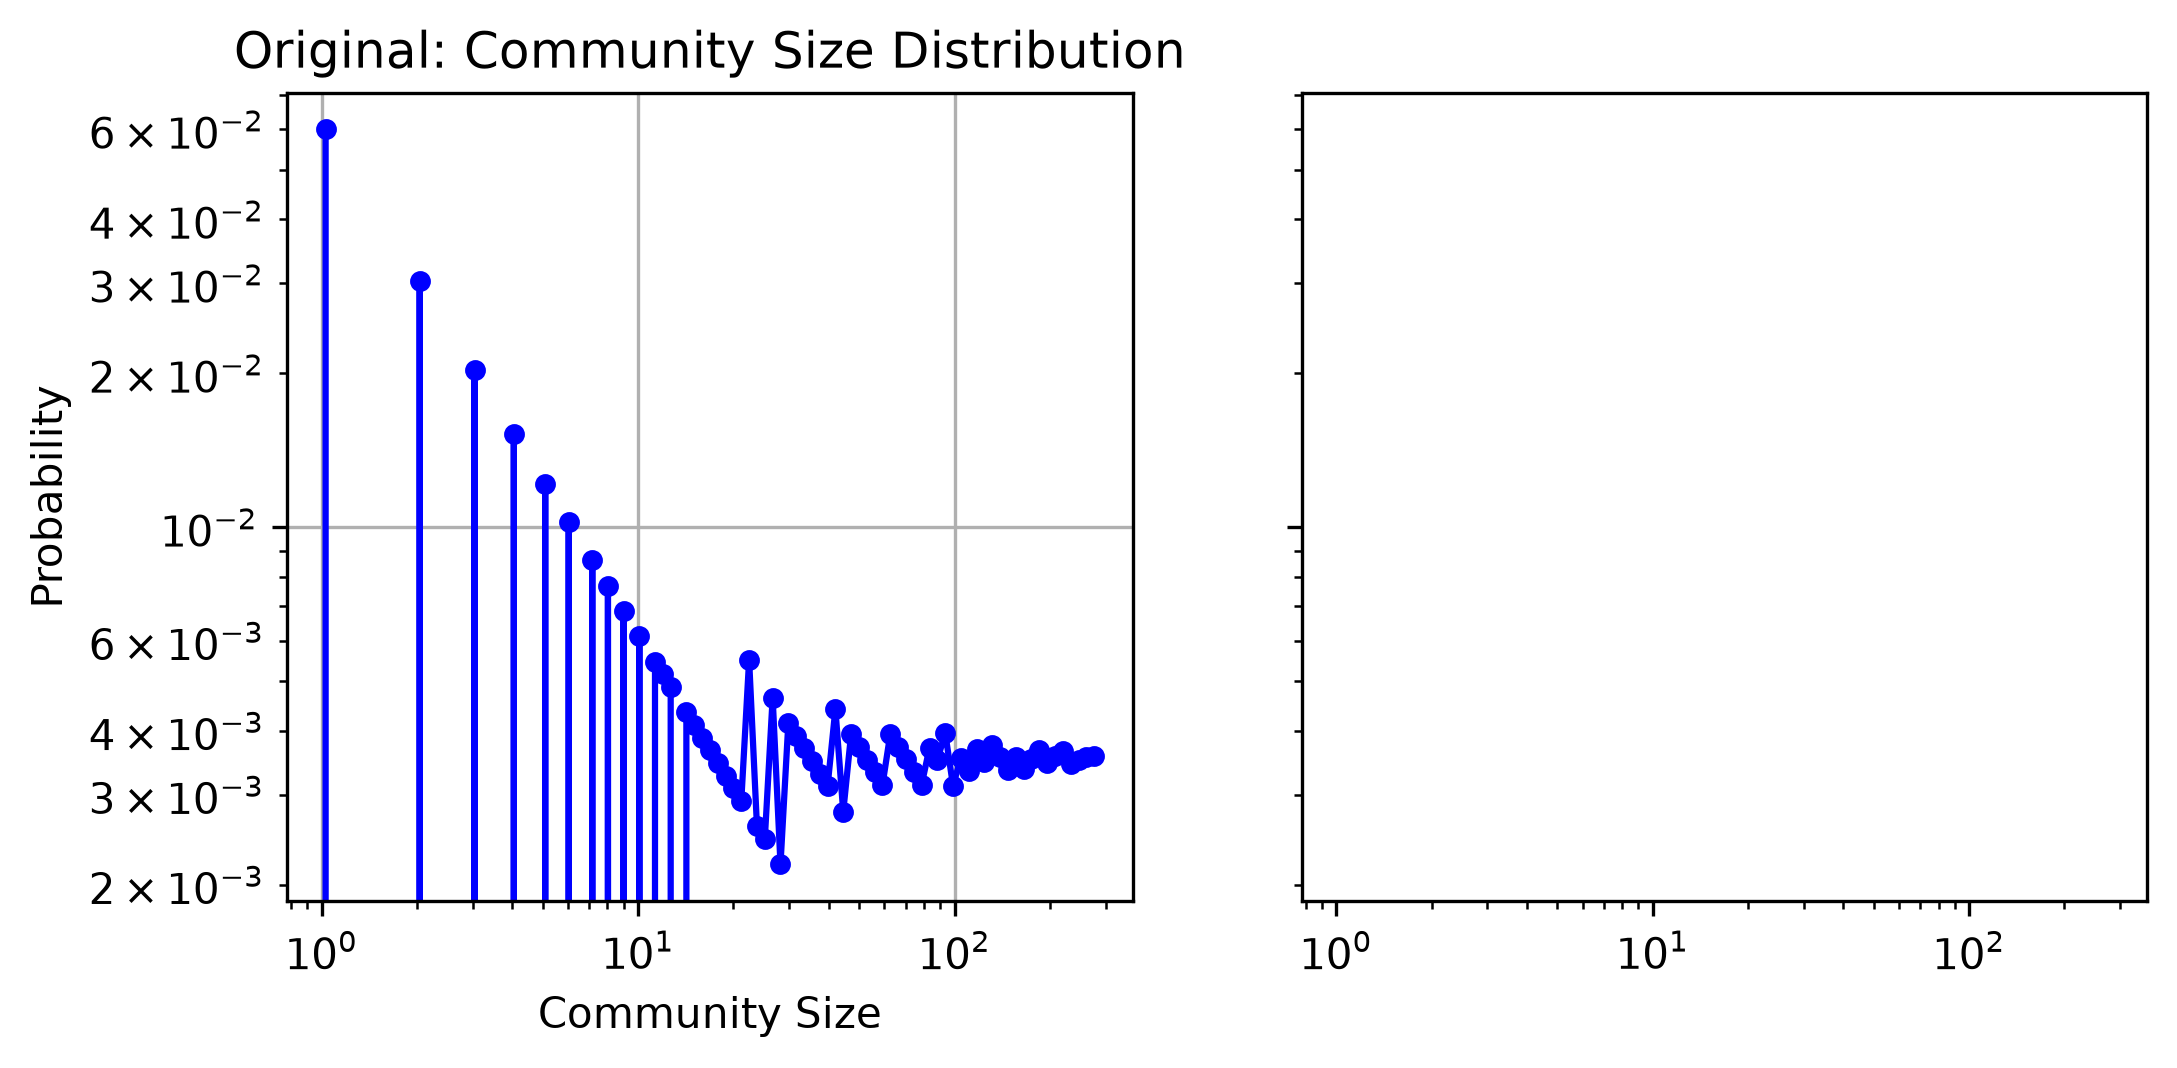

In [ ]:
from collections import Counter

community_sizes = Counter(G_parts.values())
null_community_sizes = []
for G_parts_null in partition_nulls:
    null_community_sizes.append(list(Counter(dict(G_parts_null).values())))#Troubleshoot

fig, ax = plt.subplots(1,2,figsize=(8,3.5),dpi=300,sharey=True,sharex=True)

# Plotting the community size distribution of the original dataset
org_bins = np.geomspace(1,np.max(list(community_sizes)),num=100)#Defining the smallest community as an isolated node of 1
#ax[0].hist(list(community_sizes),bins=org_bins, density=True,color = 'b',histtype='step')
counts_org, bin_edges_org = np.histogram(list(community_sizes), bins=org_bins, density=True)
bin_centers_org = np.sqrt(bin_edges_org[:-1] * bin_edges_org[1:])
ax[0].loglog(bin_centers_org, counts_org, marker='o', ms=4,color = 'b')
ax[0].loglog()
ax[0].set_title("Original: Community Size Distribution")
ax[0].set_xlabel("Community Size")
ax[0].set_ylabel("Probability")
ax[0].grid(True)
# Plotting the community size distribution of the Chung Lu Null Model of the dataset
null_bins = np.geomspace(1,np.max(list(null_community_sizes)),num=100)
#ax[1].hist(list(null_community_sizes),bins=null_bins,density=True,color = 'b',histtype='step')
counts_null, bin_edges_null = np.histogram(list(null_community_sizes), bins=null_bins, density=True)
bin_centers_null = np.sqrt(bin_edges_null[:-1] * bin_edges_null[1:])
ax[1].loglog(bin_centers_null, counts_null, marker='o', ms=4,color = 'b')
ax[1].loglog()
ax[1].set_title("Configuration: Community Size Distribution")
ax[1].set_xlabel("Community Size")
#ax[1].set_ylabel("Probability")
ax[1].tick_params(labelleft=True)
ax[1].grid(True)

plt.tight_layout()

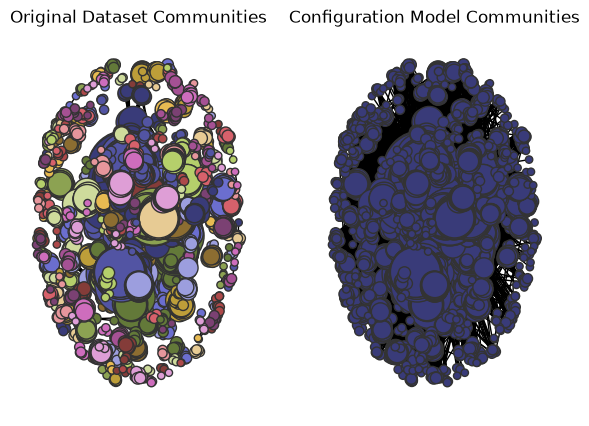

In [85]:
#Community Visualization
fig, ax = plt.subplots(1,2,figsize=(7,5),dpi=100)
#pos = nx.fruchterman_reingold_layout(G)

nx.draw(G, pos=pos,label="Original Dataset Communities", node_size=sizes, edgecolors='.2', node_color=colors_nodes, ax=ax[0])
nx.draw(G_null, pos=pos,label="Configuration Model Communities", node_size=sizes, edgecolors='.2', node_color=colors_nodes_null, ax=ax[1])
ax[0].set_title("Original Dataset Communities")
ax[1].set_title("Configuration Model Communities")
plt.show()

In [86]:
#Centrality
closeness_centrality = nx.closeness_centrality(G)
#betweeness_centrality = nx.betweenness_centrality(G,k=2000)
#eigenvector_centrality = nx.eigenvector_centrality_numpy(G)


# Sorting using a for loop
sorted_dict = {}
for key in sorted(closeness_centrality, key=closeness_centrality.get, reverse=True):
    sorted_dict[key] = closeness_centrality[key]

print("Most Central Nodes by Closeness: ", sorted_dict)
#print("Betweeness Centrality: ", betweeness_centrality)
#print("Eigenvector Centrality: ", eigenvector_centrality)


Most Central Nodes by Closeness:  {'cole1114': 0.14708279765253665, 'challam': 0.14630008031195163, 'SHE_LOVES_YOU': 0.14630008031195163, 'colognefirebird': 0.14599606259714962, 'AnEnglishGentleman': 0.14567652277577584, 'scottread1': 0.1447759466761889, 'itssohottinhere': 0.14442872250074348, 'bedintruder': 0.14442872250074348, 'GenJonesMom': 0.1432994780981881, 'Lots42': 0.1426850834047738, 'like9mexicans': 0.14188465098356445, 'alphawolf29': 0.14164626951349799, 'NoApollonia': 0.1389232005071416, 'IncidentOn57thStreet': 0.1389232005071416, 'barbsteele': 0.1389232005071416, 'brainfoods': 0.1389232005071416, 'liebkartoffel': 0.136952338554961, 'dsprox': 0.13640577005894833, 'the2belo': 0.1361561040284787, 'whowantstoknow': 0.1360828466820736, 'Lampmonster1': 0.13606820467145578, 'Dr__Acula': 0.13600966812395246, 'hupwhat': 0.13600966812395246, 'fastr1337': 0.13599504185573827, 'Forthewolfx': 0.13593656822707836, 'jaquetheduck': 0.13593656822707836, 'PervertedSmile': 0.1359073502650736

In [87]:

#Centrality
closeness_centrality_null = nx.closeness_centrality(G_null)
#betweeness_centrality = nx.betweenness_centrality(G_null)
#eigenvector_centrality = nx.eigenvector_centrality_numpy(G_null)


# Sorting using a for loop
sorted_dict_null = {}
for key in sorted(closeness_centrality_null, key=closeness_centrality_null.get, reverse=True):
    sorted_dict_null[key] = closeness_centrality_null[key]

print("Most Central Nodes by Closeness (in Null Model): ", sorted_dict_null)
#print("Betweeness Centrality: ", betweeness_centrality)
#print("Eigenvector Centrality: ", eigenvector_centrality)

Most Central Nodes by Closeness (in Null Model):  {'NoApollonia': 0.49864431846191765, 'IncidentOn57thStreet': 0.4981531642452598, 'barbsteele': 0.49778543307086615, 'brainfoods': 0.4972348531399779, 'challam': 0.4825283243887895, 'cole1114': 0.48132286462050916, 'colognefirebird': 0.47768595041322315, 'the2belo': 0.4775731822474032, 'GenJonesMom': 0.4760560065890105, 'Lampmonster1': 0.4757761053621825, 'Dr__Acula': 0.47477118047406713, 'dsprox': 0.4746597841389019, 'armenianlover': 0.47438152186657284, 'giveuptheghost': 0.4740480374926772, 'Nwsamurai': 0.4739925023430178, 'SHE_LOVES_YOU': 0.4738259749385174, 'JohnWilmontwannabe': 0.4737704918032787, 'pjhollow': 0.4735486891385768, 'metalmusic': 0.4734932709186659, 'ThereisnoTruth': 0.4734378656681488, 'HonorAmongSteves': 0.4733270940570894, 'Violent_Milk': 0.47321637426900587, 'tittyjack': 0.47321637426900587, 'MaynardJayTwa': 0.4731057062675398, 'liebkartoffel': 0.4730503916754355, 'aseclear': 0.47299509001636664, 'dunkleheit': 0.472

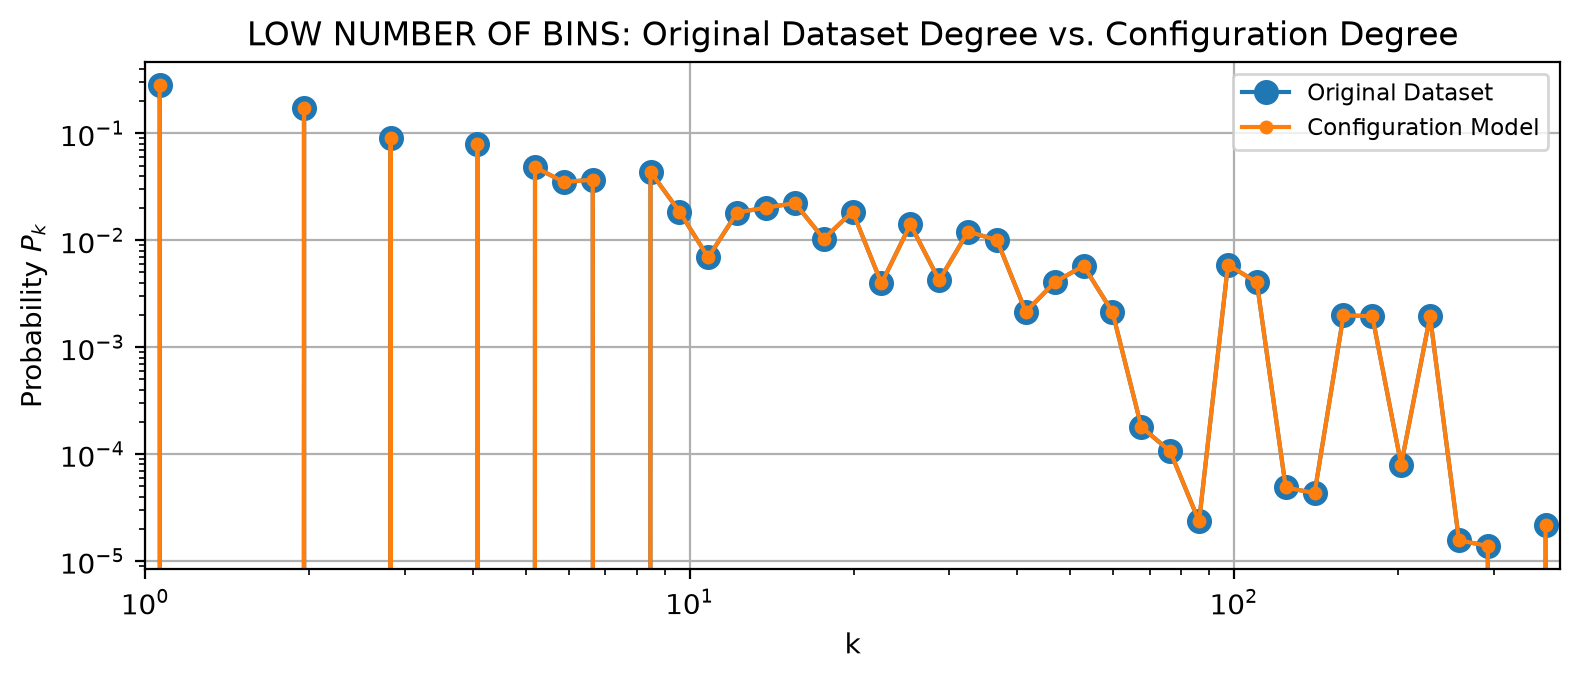

In [101]:
actual_deg_sequence = list(deg.values())
actual_deg_sequence_null = list(deg_null.values())

#---Plotting the Degree Distribution 'k'
#Starting the plotting process
fig, ax = plt.subplots(1,1,figsize=(8,3.5),dpi=200,sharex=True,sharey=True)

bins = np.geomspace(1,np.max(actual_deg_sequence),num=50)
counts, bin_edges = np.histogram(actual_deg_sequence, bins=bins, density=True)
bin_centers = np.sqrt(bin_edges[:-1] * bin_edges[1:])
ax.loglog(bin_centers, counts, marker='o', ms=8, label="Original Dataset")


bins_null = np.geomspace(1,np.max(actual_deg_sequence_null),num=50)
counts_null, bin_edges_null = np.histogram(actual_deg_sequence_null, bins=bins_null, density=True)
bin_centers_null = np.sqrt(bin_edges_null[:-1] * bin_edges_null[1:])
ax.loglog(bin_centers_null, counts_null, marker='o', ms=4, label="Configuration Model")

#LEGACY:
#ax[1].hist(actual_deg_sequence_null,label="Configuration Model Sample",density=True)#Plotting the configuration model graph empirical data
#ax.hist(num_edges_list_chunglu,label="Chung Lu Model Sample",density=True)#Plotting the Chung Lu model graph empirical data
#ax.plot(L,P_l, color = 'r',label="Theoretical Distribution") #Plotting the Theoretical
#handles, labels = ax.get_legend_handles_labels()
#ax[1].legend(handles=handles, labels=labels,loc="upper right",fontsize="small")

#Specifying figure details below:
ax.loglog()

#Specifying figure details below:
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=labels,loc="upper right",fontsize="small")
ax.set_title("LOW NUMBER OF BINS: Original Dataset Degree vs. Configuration Degree")
ax.set_xlabel("k")
ax.set_ylabel("Probability $P_{k}$")
true_min=min(min(actual_deg_sequence), min(actual_deg_sequence_null))
true_max=max(max(actual_deg_sequence), max(actual_deg_sequence_null))
ax.set_xlim(true_min,true_max)
ax.grid(True)
plt.tight_layout()
plt.show()


The tail of the degree distribution looked off, relative to a power law. I was curious if my binning was incorrect so I decided to investigate further by increasing the binning:

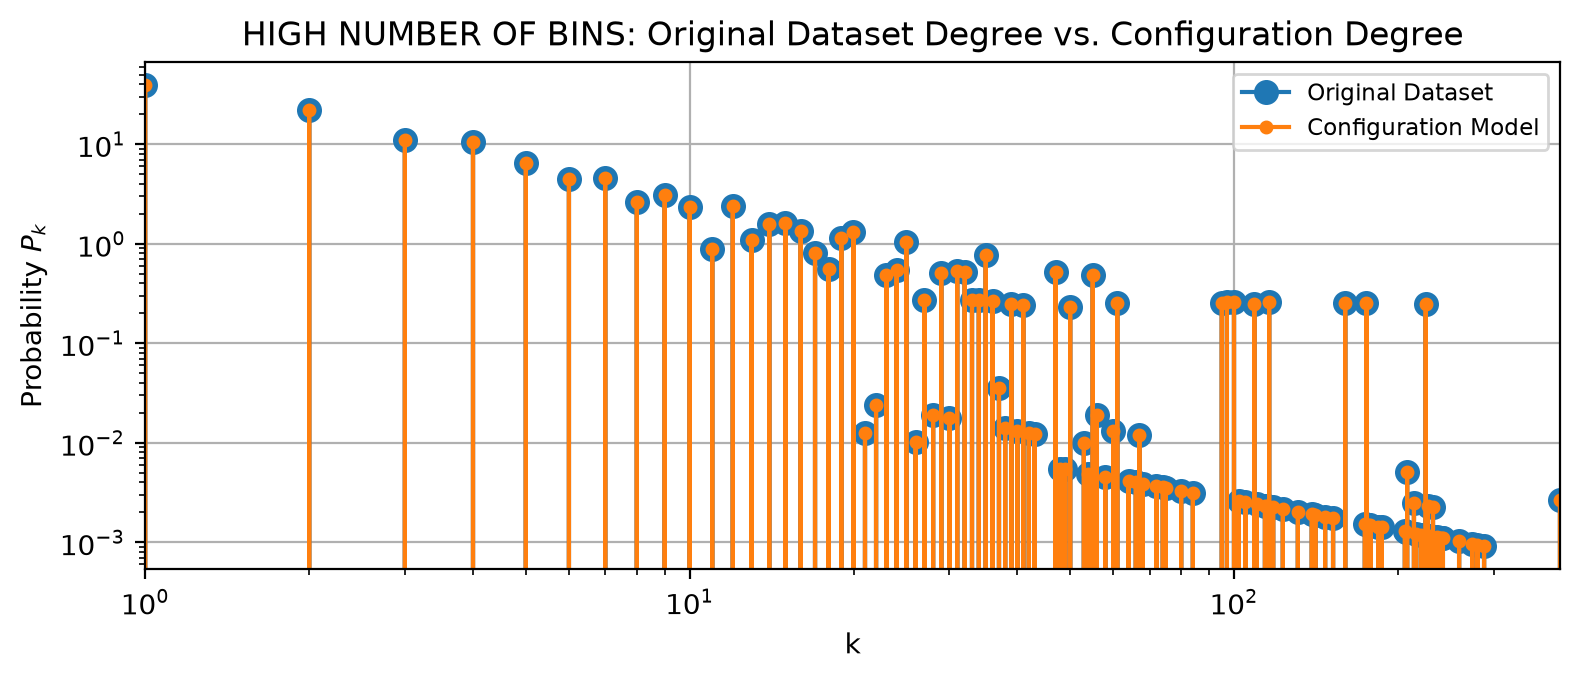

In [99]:
actual_deg_sequence = list(deg.values())
actual_deg_sequence_null = list(deg_null.values())

#---Plotting the Degree Distribution 'k'
#Starting the plotting process
fig, ax = plt.subplots(1,1,figsize=(8,3.5),dpi=200,sharex=True,sharey=True)

bins = np.geomspace(1,np.max(actual_deg_sequence),num=6400)
counts, bin_edges = np.histogram(actual_deg_sequence, bins=bins, density=True)
bin_centers = np.sqrt(bin_edges[:-1] * bin_edges[1:])
ax.loglog(bin_centers, counts, marker='o', ms=8, label="Original Dataset")


bins_null = np.geomspace(1,np.max(actual_deg_sequence_null),num=6400)
counts_null, bin_edges_null = np.histogram(actual_deg_sequence_null, bins=bins_null, density=True)
bin_centers_null = np.sqrt(bin_edges_null[:-1] * bin_edges_null[1:])
ax.loglog(bin_centers_null, counts_null, marker='o', ms=4, label="Configuration Model")

#LEGACY:
#ax[1].hist(actual_deg_sequence_null,label="Configuration Model Sample",density=True)#Plotting the configuration model graph empirical data
#ax.hist(num_edges_list_chunglu,label="Chung Lu Model Sample",density=True)#Plotting the Chung Lu model graph empirical data
#ax.plot(L,P_l, color = 'r',label="Theoretical Distribution") #Plotting the Theoretical
#handles, labels = ax.get_legend_handles_labels()
#ax[1].legend(handles=handles, labels=labels,loc="upper right",fontsize="small")

#Specifying figure details below:
ax.loglog()

#Specifying figure details below:
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=labels,loc="upper right",fontsize="small")
ax.set_title("HIGH NUMBER OF BINS: Original Dataset Degree vs. Configuration Degree")
ax.set_xlabel("k")
ax.set_ylabel("Probability $P_{k}$")
true_min=min(min(actual_deg_sequence), min(actual_deg_sequence_null))
true_max=max(max(actual_deg_sequence), max(actual_deg_sequence_null))
ax.set_xlim(true_min,true_max)
ax.grid(True)
plt.tight_layout()
plt.show()


Degree distribution looks super strange. It looks almost like 2 power law distributions? Like there are 2 classes of users aboard reddit?

The more bins I add, more of this double-set of probabilities gets pulled out. Unsure as to why.

Is this because there's a group of users that are only active on r/all? It's interesting however that there's such a distinct 2nd power law.

What sub-reddits and posts does the latter curve relate to vs. the former curve?

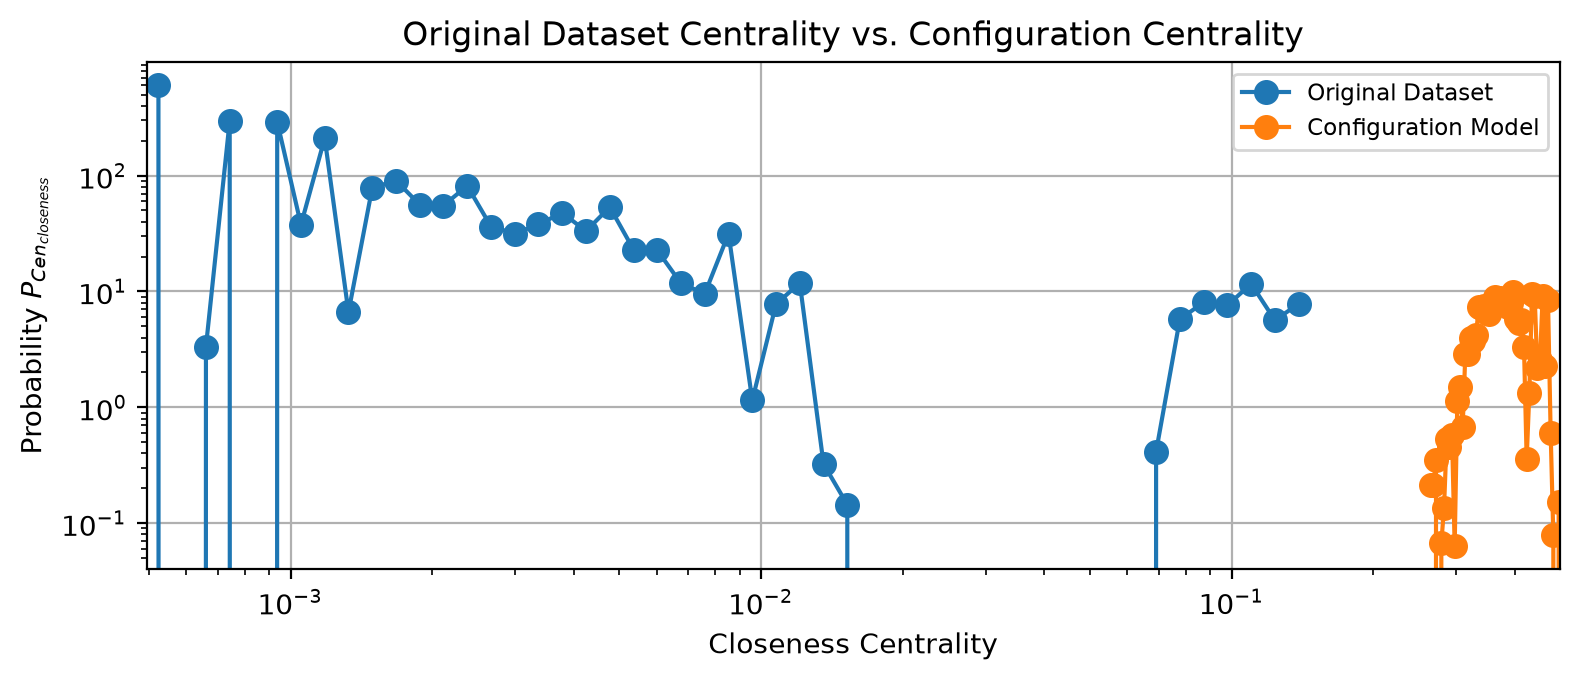

In [89]:
centrality_sequence = list(sorted_dict.values())
centrality_sequence_null = list(sorted_dict_null.values())
#---Plotting the Centrality
#Starting the plotting process
fig, ax = plt.subplots(1,1,figsize=(8,3.5),dpi=200,sharex=True,sharey=True)

#Finding the minimum value for log-log binning

centrality_sequence=np.asarray(centrality_sequence)
centrality_sequence_min= np.amin(centrality_sequence[centrality_sequence != np.amin(centrality_sequence)])
centrality_sequence_null=np.asarray(centrality_sequence_null)
centrality_sequence_null_min= np.amin(centrality_sequence_null[centrality_sequence_null != np.amin(centrality_sequence_null)])

bins = np.geomspace(centrality_sequence_min,np.max(centrality_sequence))
counts, bin_edges = np.histogram(centrality_sequence, bins=bins, density=True)
bin_centers = np.sqrt(bin_edges[:-1] * bin_edges[1:])
ax.loglog(bin_centers, counts, marker='o', ms=8, label="Original Dataset")


bins_null = np.geomspace(centrality_sequence_null_min,np.max(centrality_sequence_null))
counts_null, bin_edges_null = np.histogram(centrality_sequence_null, bins=bins_null, density=True)
bin_centers_null = np.sqrt(bin_edges_null[:-1] * bin_edges_null[1:])
ax.loglog(bin_centers_null, counts_null, marker='o', ms=8, label="Configuration Model")

#Specifying figure details below:
ax.loglog()

#Specifying figure details below:
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=labels,loc="upper right",fontsize="small")
ax.set_title("Original Dataset Centrality vs. Configuration Centrality")
ax.set_xlabel("Closeness Centrality")
ax.set_ylabel("Probability $P_{Cen_{closeness}}$")
true_min=min([(centrality_sequence_min), (centrality_sequence_null_min)])
true_max=max([max(centrality_sequence), max(centrality_sequence_null)])
ax.set_xlim(true_min,true_max)
ax.grid(True)
plt.tight_layout()
plt.show()

How much of this is explaine by sub-reddit and sub-reddit size? Are there really more central users here?

[1. 1. 1. ... 1. 1. 1.]
[0. 0. 0. ... 0. 0. 0.]


/tmp/ipykernel_606306/2760581411.py:37: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(true_min,true_max)


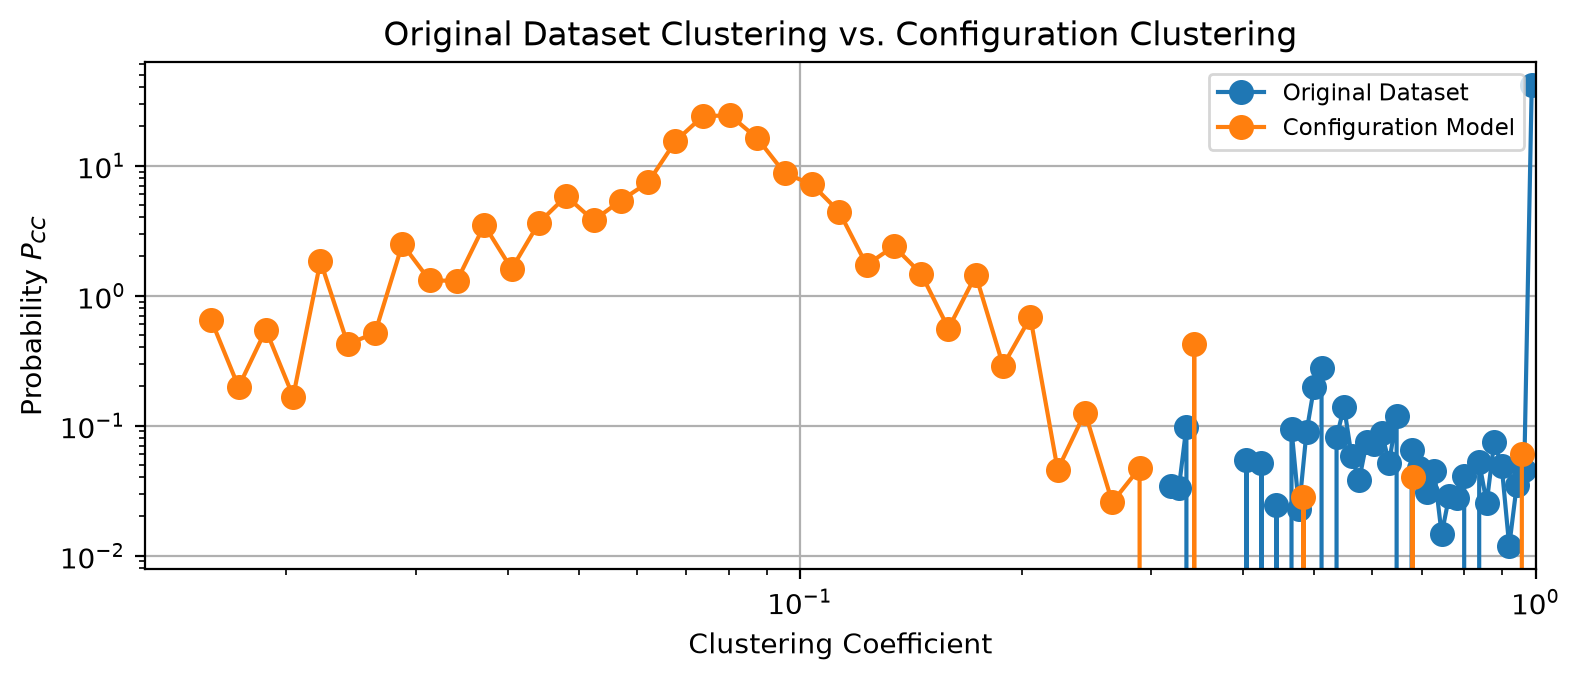

In [90]:
#---Plotting the Average Clustering Coefficient 'CC'
#Starting the plotting process
fig, ax = plt.subplots(1,1,figsize=(8,3.5),dpi=200,sharex=True,sharey=True)

#Finding the minimum value for log-log binning
cc=np.asarray(cc)
cc_min= np.amin(cc[cc != np.amin(cc)])
#PROBLEM Sampling caused clustering to either be 1 or 0. Interesting.
#cc_max= np.amax(cc[cc != np.amax(cc)])#Clustering very high so attempting to get the second largest max
cc_null=np.asarray(cc_null)
cc_null_min= np.amin(cc_null[cc_null != np.amin(cc_null)])

print(cc)
print(cc_null)

bins = np.geomspace(cc_min,np.max(cc))
counts, bin_edges = np.histogram(cc, bins=bins, density=True)
bin_centers = np.sqrt(bin_edges[:-1] * bin_edges[1:])
ax.loglog(bin_centers, counts, marker='o', ms=8, label="Original Dataset")

bins_null = np.geomspace(cc_null_min,np.max(cc_null))
counts_null, bin_edges_null = np.histogram(cc_null, bins=bins_null, density=True)
bin_centers_null = np.sqrt(bin_edges_null[:-1] * bin_edges_null[1:])
ax.loglog(bin_centers_null, counts_null, marker='o', ms=8, label="Configuration Model")

#Specifying figure details below:
ax.loglog()

#Specifying figure details below:
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=labels,loc="upper right",fontsize="small")
ax.set_title("Original Dataset Clustering vs. Configuration Clustering")
ax.set_xlabel("Clustering Coefficient")
ax.set_ylabel("Probability $P_{CC}$")
true_min=min(min(cc), min(cc_null))
true_max=max(max(cc), max(cc_null))
ax.set_xlim(true_min,true_max)
ax.grid(True)
plt.tight_layout()
plt.show()

Note, here due to the way I sampled and constructed the network the clustering coefficient became either a 1 or 0 in the original graph. This is because I defined each post as a component of fully-connected comments. (i.e., that comments that appear on the same post are thereby connected.)

By nature this excludes posts with no comments, and leaves us with either posts containing 1 comment, or fully connected comments should there be more than 1 on a given post.
